In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/horses_combined.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

236

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

5.423728813559322

In [7]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+2)

2  k_max:  9
3  k_max:  6
5  k_max:  5
6  k_max:  5
7  k_max:  4
10  k_max:  4
11  k_max:  4


# Init Fitter

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.006683
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.047389


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 640},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1891},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 816},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 2554},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 755},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 7236},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 5386},
 {'name': 'four_loop

# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,5]},
                {'m': 7,  'k': [1,4]},
                {'m': 10, 'k': [1,4]},
                {'m': 11, 'k': [1,4]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-11 14:50:07,279] A new study created in memory with name: no-name-c028fd3d-8dbb-4b5e-8c94-0e14fe5f06fe


Grid Search requires 8 trials...


[I 2025-02-11 14:50:24,155] Trial 0 finished with value: 7.313878320140073 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 7.313878320140073.
[I 2025-02-11 14:50:41,880] Trial 1 finished with value: 7.627408055813934 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 7.313878320140073.
[I 2025-02-11 14:50:56,351] Trial 2 finished with value: 8.262344251719092 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 7.313878320140073.
[I 2025-02-11 14:51:15,270] Trial 3 finished with value: 7.794866726699393 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 7.313878320140073.
[I 2025-02-11 14:51:30,905] Trial 4 finished with value: 7.079602966357483 and parameters: {'m': 2, 'k': 4}. Best is trial 4 with value: 7.079602966357483.
[I 2025-02-11 14:51:47,154] Trial 5 finished with value: 8.38981814452935 and parameters: {'m': 2, 'k': 1}. Best is trial 4 with value: 7.079602966357483.
[I 2025-02-11 14:52:02,916] Trial 6 finished with value: 6.548744

Grid Search requires 5 trials...


[I 2025-02-11 14:52:52,705] Trial 0 finished with value: 7.241039459282354 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 7.241039459282354.
[I 2025-02-11 14:53:25,096] Trial 1 finished with value: 7.689068860748642 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 7.241039459282354.
[I 2025-02-11 14:53:58,149] Trial 2 finished with value: 7.106930357438886 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 7.106930357438886.
[I 2025-02-11 14:54:31,134] Trial 3 finished with value: 6.693414594738399 and parameters: {'m': 3, 'k': 4}. Best is trial 3 with value: 6.693414594738399.
[I 2025-02-11 14:55:09,363] Trial 4 finished with value: 6.181627360378579 and parameters: {'m': 3, 'k': 5}. Best is trial 4 with value: 6.181627360378579.
[I 2025-02-11 14:55:09,364] A new study created in memory with name: no-name-708c310d-619f-4b01-9321-2ebcc38bd047


Grid Search requires 4 trials...


... (6 outputs left out)

[I 2025-02-11 15:38:01,379] Trial 0 finished with value: 6.530116058486256 and parameters: {'m': 10, 'k': 3}. Best is trial 0 with value: 6.530116058486256.
[I 2025-02-11 15:44:18,984] Trial 1 finished with value: 6.636241439347723 and parameters: {'m': 10, 'k': 2}. Best is trial 0 with value: 6.530116058486256.
[I 2025-02-11 15:48:30,539] Trial 2 finished with value: 6.657943793805747 and parameters: {'m': 10, 'k': 1}. Best is trial 0 with value: 6.530116058486256.
[I 2025-02-11 15:48:30,540] A new study created in memory with name: no-name-adf26a5f-1157-41e8-890b-971b66df94af


Grid Search requires 3 trials...


[I 2025-02-11 16:18:16,347] Trial 0 finished with value: 6.512929651775556 and parameters: {'m': 11, 'k': 3}. Best is trial 0 with value: 6.512929651775556.
[I 2025-02-11 16:26:08,259] Trial 1 finished with value: 6.50251251105604 and parameters: {'m': 11, 'k': 2}. Best is trial 1 with value: 6.50251251105604.
[I 2025-02-11 16:31:53,836] Trial 2 finished with value: 6.491893182012817 and parameters: {'m': 11, 'k': 1}. Best is trial 2 with value: 6.491893182012817.


Best parameters:  {'m': 5, 'k': 4}
Best energy:  8.557486664340527
Best KL-divergence:  0.05604991623562077
Best KLD augumented energy: 6.122199001521597
Best P matrix:
 [[9.21411879e-01 2.86563573e-05 1.81757103e-02 9.38875331e-01
  9.61150641e-01]
 [2.86563573e-05 8.46517381e-01 5.02604468e-02 2.86559270e-05
  2.83214178e-02]
 [1.81757103e-02 5.02604468e-02 9.99998126e-01 9.27276940e-01
  8.94977397e-01]
 [9.38875331e-01 2.86559270e-05 9.27276940e-01 9.92745286e-01
  6.09386879e-01]
 [9.61150641e-01 2.83214178e-02 8.94977397e-01 6.09386879e-01
  1.73373568e-01]]
Best l vector:
 [0.42432328 0.30814031 0.18518804 0.08153835 0.00081002]


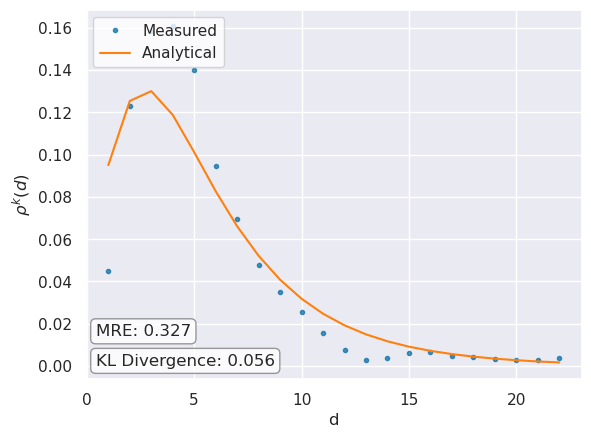

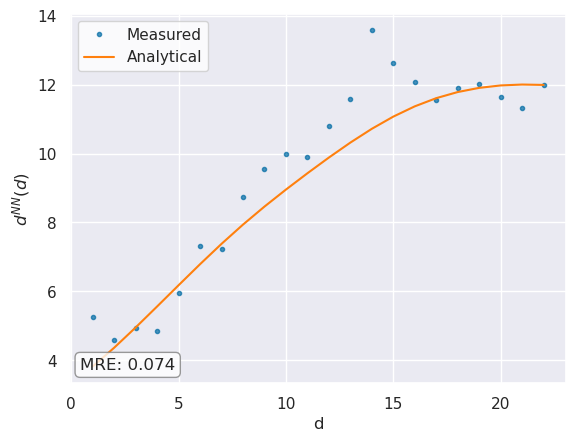

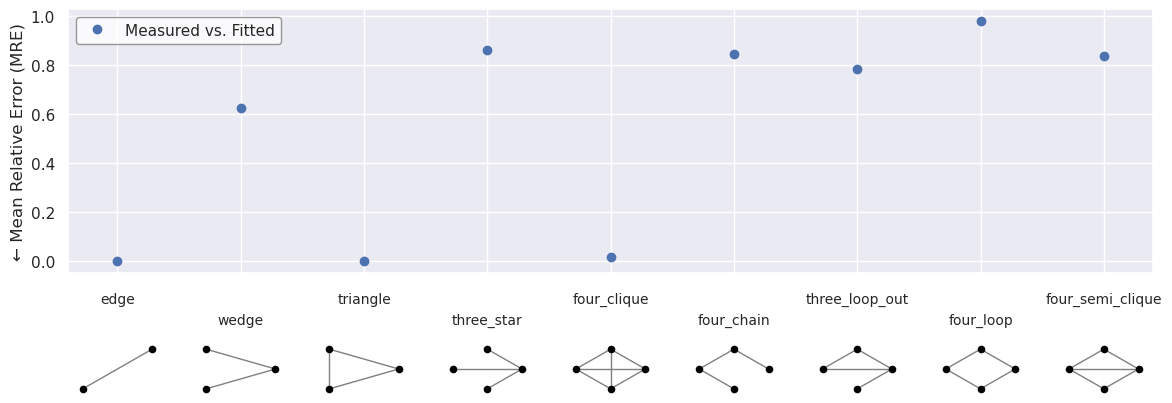

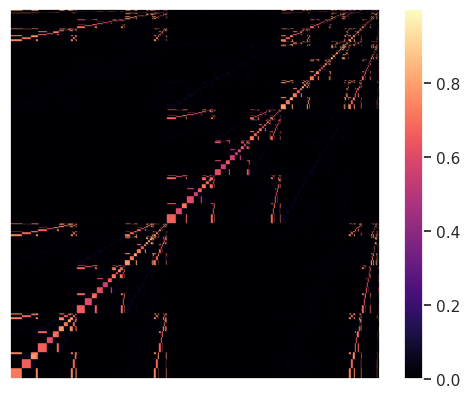

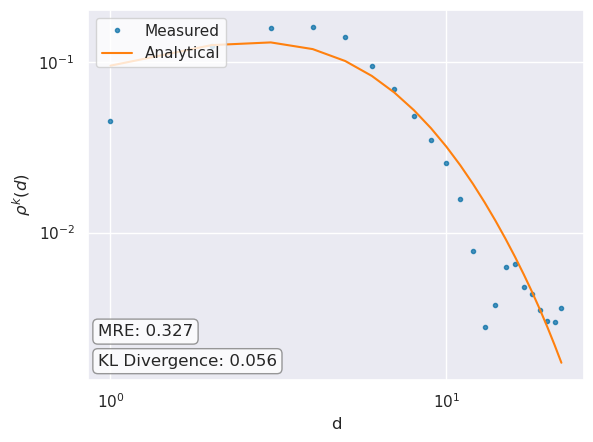

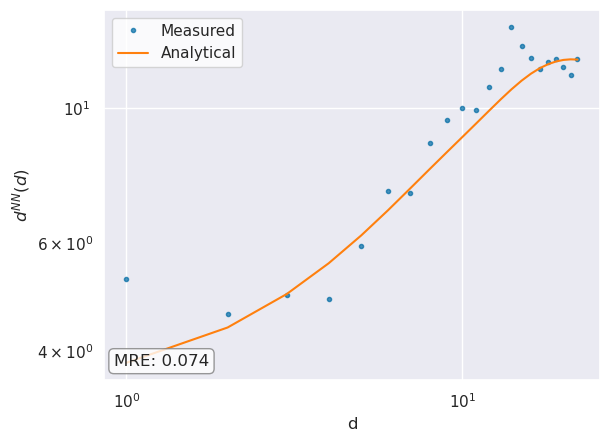

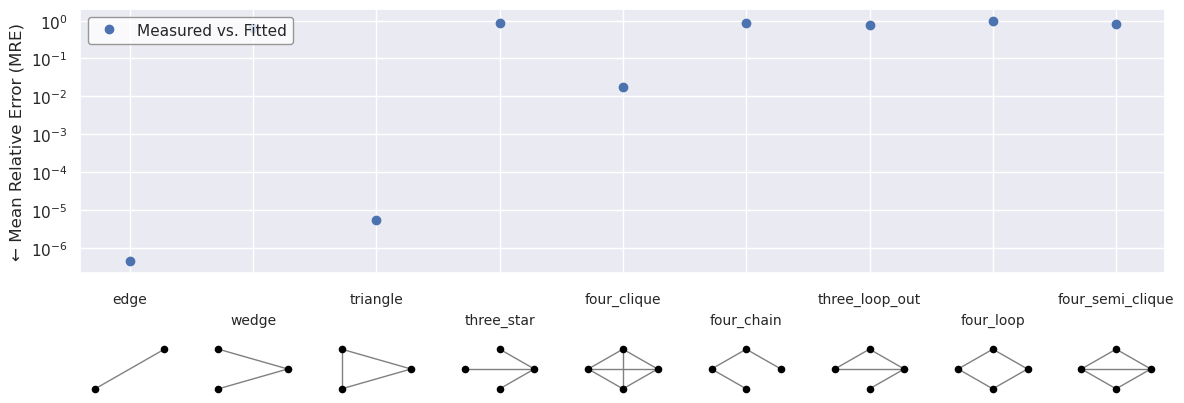

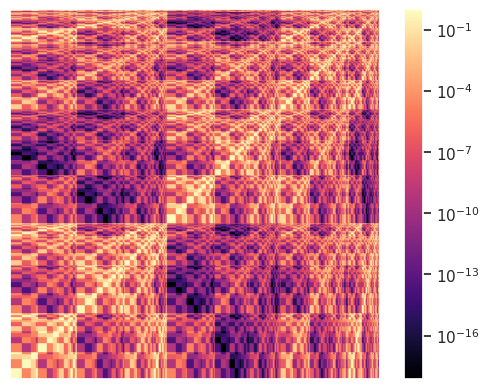

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_log_plot.pdf"
)

# Bootstrapping Stability

In [12]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [1:13:32<00:00, 147.08s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.538457
Energy = 8.45 (8.37, 8.71)
l = [0.42 (0.37, 0.49), 0.36 (0.21, 0.41), 0.17 (0.11, 0.23), 0.05 (0.00, 0.17), 0.00 (0.00, 0.05)]
P = [
[1.00 (0.64, 1.00), 0.00 (0.00, 0.00), 0.63 (0.00, 0.74), 0.13 (0.00, 1.00), 0.40 (0.00, 1.00)],

[0.00 (0.00, 0.00), 0.73 (0.60, 1.00), 0.00 (0.00, 0.73), 0.04 (0.00, 1.00), 0.12 (0.00, 0.89)],

[0.63 (0.00, 0.74), 0.00 (0.00, 0.73), 0.08 (0.00, 1.00), 0.02 (0.00, 0.99), 0.25 (0.00, 0.97)],

[0.13 (0.00, 1.00), 0.04 (0.00, 1.00), 0.02 (0.00, 0.99), 0.81 (0.00, 1.00), 0.26 (0.00, 1.00)],

[0.40 (0.00, 1.00), 0.12 (0.00, 0.89), 0.25 (0.00, 0.97), 0.26 (0.00, 1.00), 0.35 (0.00, 1.00)]
]


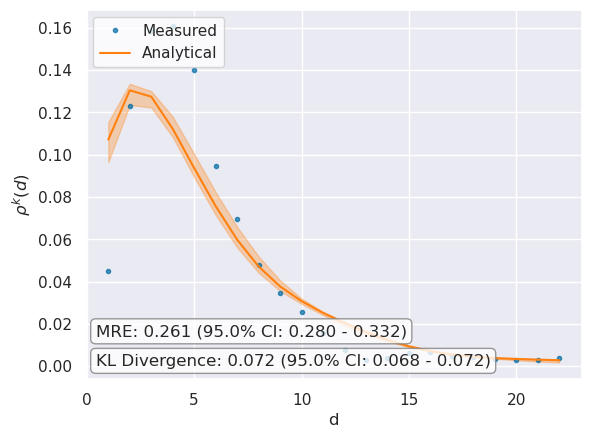

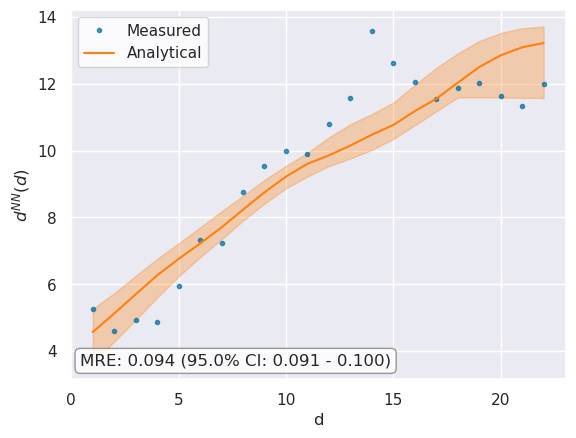

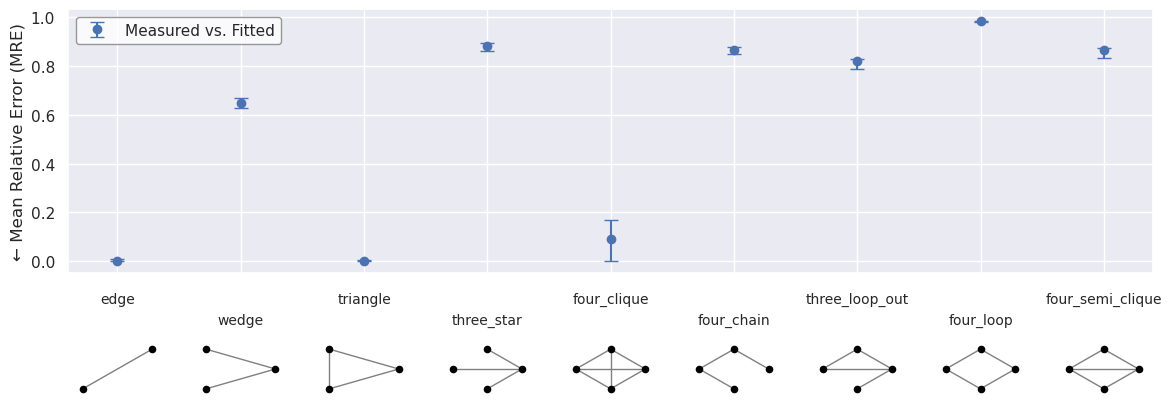

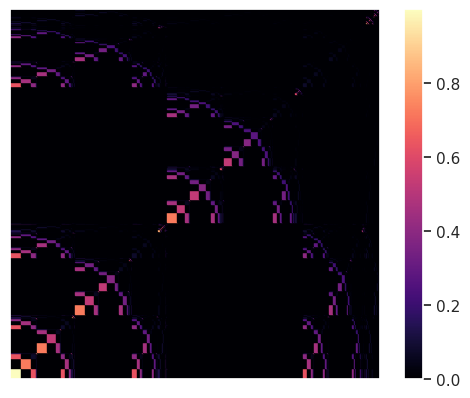

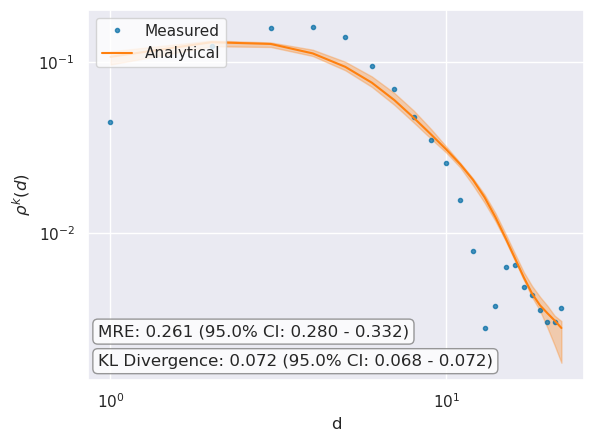

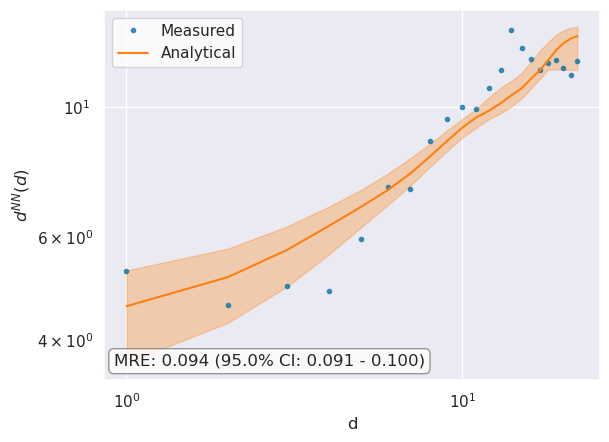

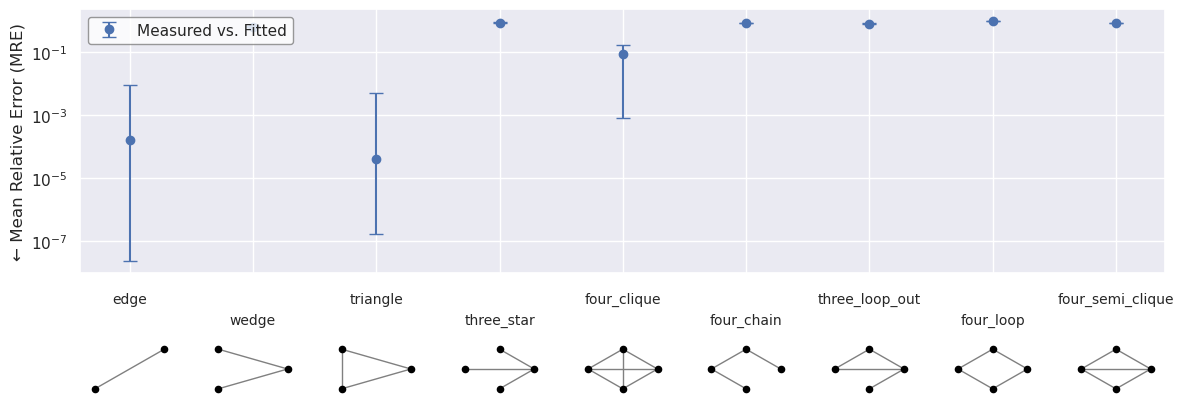

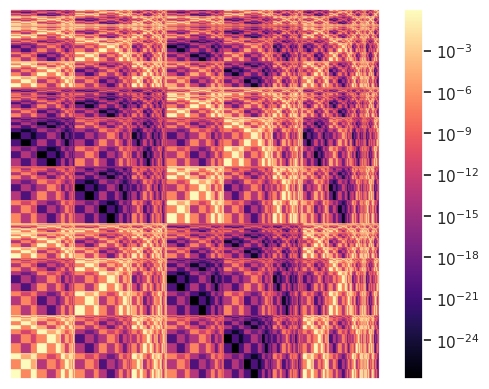

In [13]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_log_plot.pdf"
)

In [14]:
mfnf.P

array([[9.99746169e-01, 1.93120911e-07, 6.31309945e-01, 1.33987483e-01,
        3.98901192e-01],
       [1.93120911e-07, 7.25391916e-01, 1.92681693e-05, 3.92052175e-02,
        1.18242839e-01],
       [6.31309945e-01, 1.92681693e-05, 7.63056237e-02, 1.66071424e-02,
        2.45151962e-01],
       [1.33987483e-01, 3.92052175e-02, 1.66071424e-02, 8.13838067e-01,
        2.64399515e-01],
       [3.98901192e-01, 1.18242839e-01, 2.45151962e-01, 2.64399515e-01,
        3.49015529e-01]])

In [15]:
mfnf.l

array([0.4185406 , 0.3630122 , 0.16759747, 0.05279343, 0.00264969])

# Generate Variants

Initializing...
0.003614187240600586
Calculating betweenness...
Done.
Calculating node positions...
Done.


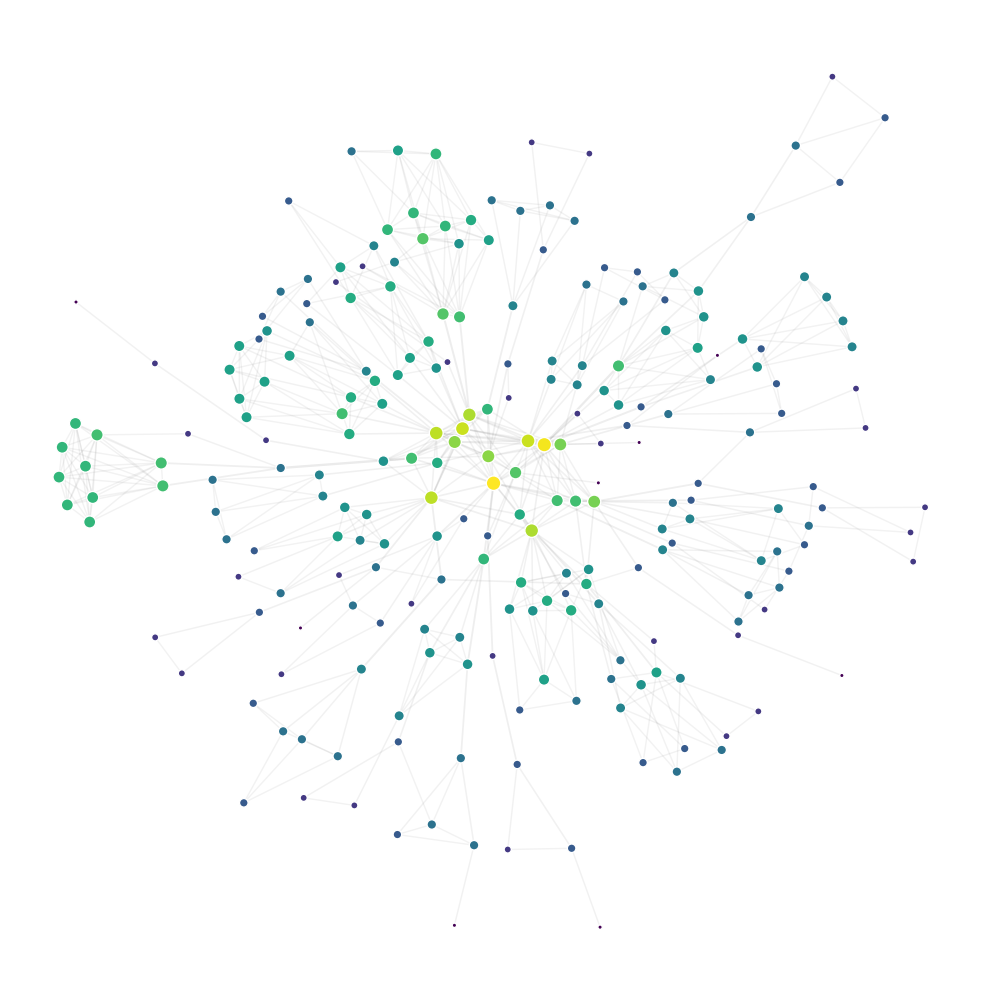

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 127.87it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


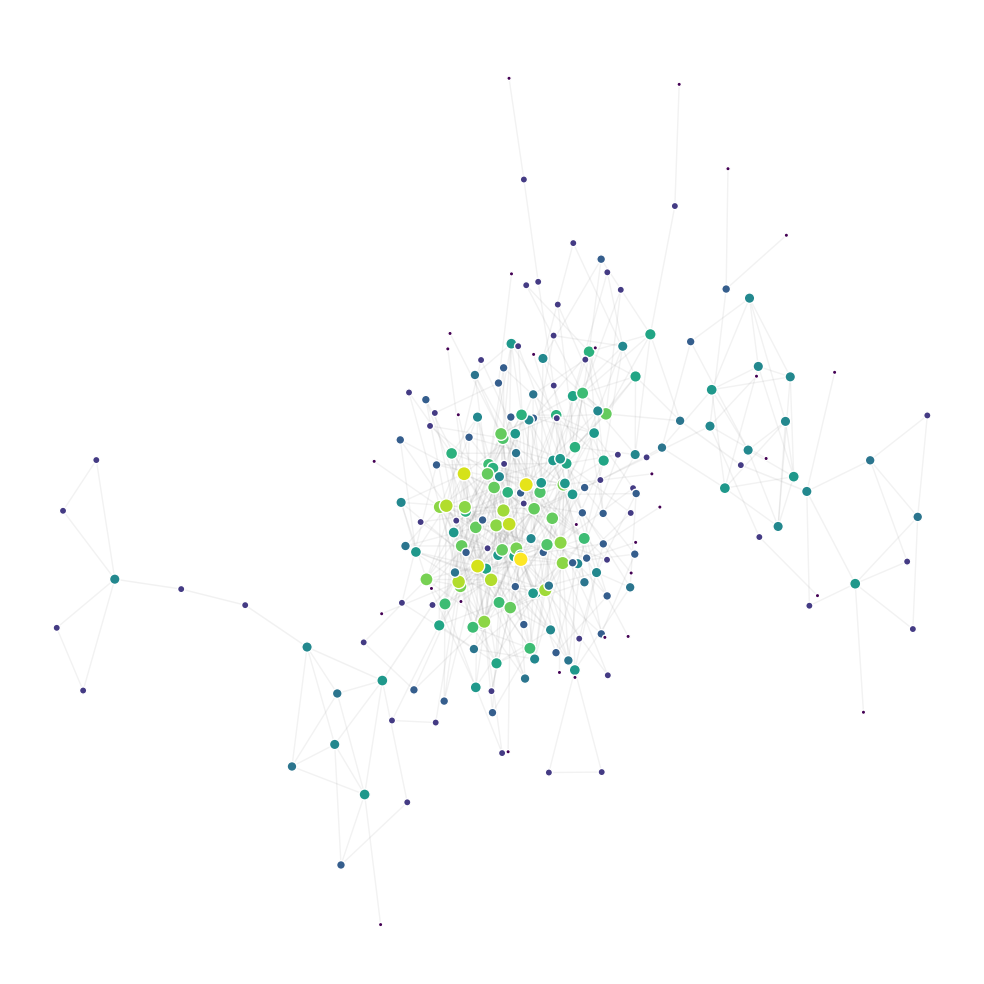

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 115.28it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


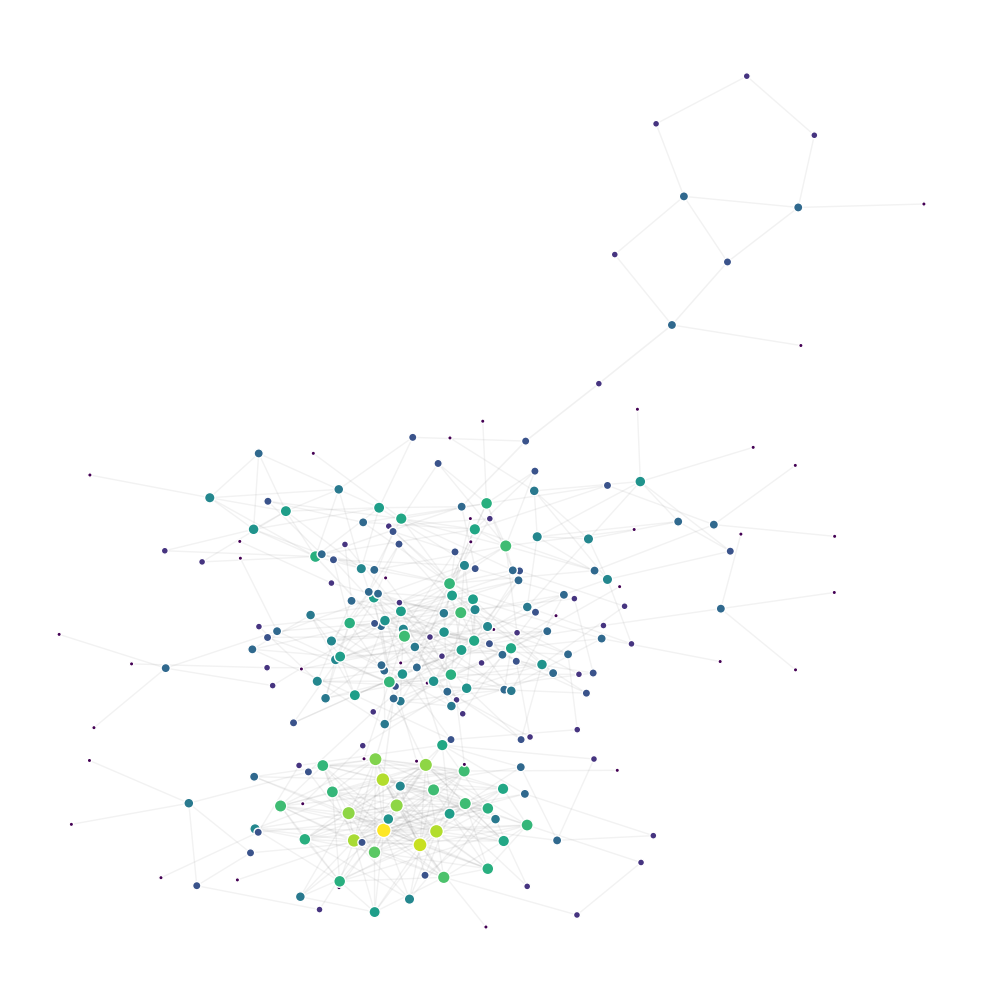

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 144.37it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


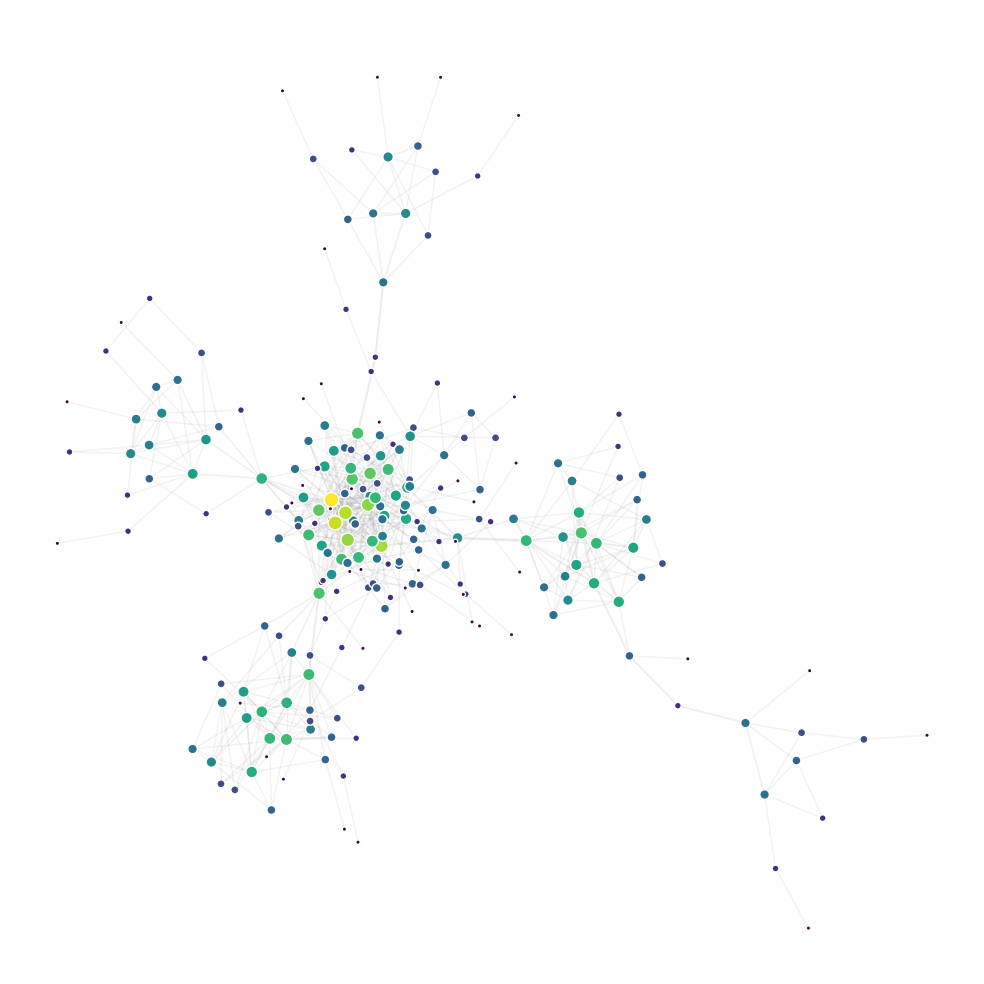

In [16]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/horses_combined_variants.pdf"
    },
    filename = "variant_networks/horses_combined_variants.graphml"
)

In [17]:
import pickle
with open('./test_networks/horses_combined_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)